# K-Means Samsung — ¿existe evidencia de estructura agrupable?

**Diagnóstico complementario e independiente** del notebook de K-Means y del notebook de estabilidad por submuestreo. No modifica los agrupamientos previos.

Sobre los mismos clientes de **TRAIN**, con las mismas tres configuraciones de variables A/B/C y escalado Z-score (`ddof=1`), se evalúan:

1. **Hopkins** (100 o 40 repeticiones) para detectar desviaciones de una distribución espacial uniforme en el rectángulo observado.
2. **Gap Statistic** de Tibshirani, Walther y Hastie para K = 1…10, con referencias uniformes en la caja original y en coordenadas principales (PCA).
3. **Comparación aleatorizada de la Silhouette** de K-Means con dos referencias por permutación: (a) independiente por columna y (b) independiente dentro de estratos *activo/inactivo Samsung últimos 12 meses*.

**Advertencia esencial:** evidencia contra una referencia elegida **no demuestra** por sí sola la existencia de categorías naturales. Hopkins puede resultar elevado por ceros, asimetría, correlaciones o límites del espacio factible. Las permutaciones conservan valores marginales pero rompen algunas restricciones entre variables (especialmente el ratio). Interpretar los tres análisis conjuntamente y junto a la estabilidad e interpretabilidad.

**No se usan las respuestas de T2 ni variables de encuesta.** La cohorte y la winsorización provienen del CSV exportado por R.

In [1]:
import sys
import numpy
import pandas
import matplotlib
import sklearn
import scipy
import seaborn

versiones = {
    "Python": sys.version.split()[0],
    "NumPy": numpy.__version__,
    "Pandas": pandas.__version__,
    "Matplotlib": matplotlib.__version__,
    "Scikit-learn": sklearn.__version__,
    "SciPy": scipy.__version__,
    "Seaborn": seaborn.__version__,
}

for paquete, version in versiones.items():
    print(f"{paquete}: {version}")

Python: 3.13.12
NumPy: 2.5.4
Pandas: 3.1.1
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
SciPy: 1.18.1
Seaborn: 0.13.2


In [2]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

## 0. Configuración

- `MODO = "exploratorio"` ejecuta menos referencias para verificar el procedimiento. **No usar resultados exploratorios como evidencia concluyente.**
- Para resultados de la tesis, cambiar a `MODO = "final"` (más réplicas y menor resolución del error Monte Carlo).
- `N_INIT_GAP` se mantiene igual para los datos reales y sus referencias (10 en modo exploratorio, 30 en modo final); `N_INIT_SIL=30` reproduce el convenio del K-Means principal.
- Si quieres más candidatos para la comparación aleatorizada, amplía `CANDIDATOS`. La evaluación completa de Gap ya abarca K = 1…10 en A, B y C.
- El notebook guarda resultados en una carpeta propia y **no sobrescribe** los archivos previos.

In [3]:
from __future__ import annotations
import hashlib
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from IPython.display import display
from config_matrices import MIN_MONETARY_T1, TAG, CARPETA_SALIDA, ruta_matrices, cargar_W_train

SEMILLA = 123
MODO = "final"     # "exploratorio" o "final"
RUTA_CSV_MANUAL = f"../../data/matrices/matrices_data{TAG}.csv"
N_INIT_GAP = 30 if MODO == "final" else 10  # mismo n_init en datos reales/referencias Gap
N_INIT_SIL = 30           # igual que el ajuste principal
MAX_ITER = 400
K_GAP = list(range(1, 11))

CANDIDATOS = [
    ("A_RFM_3", 2),
    ("B_RFM_ratio_4", 3),
    ("B_RFM_ratio_4", 4),
    ("C_W_6", 2),
    ("C_W_6", 3),
    ("C_W_6", 5),
]



if MODO == "exploratorio":
    B_GAP = 19
    B_PERM = 29
    R_HOPKINS = 40
    B_HOPKINS_PERM = 19
elif MODO == "final":
    B_GAP = 99
    B_PERM = 199
    R_HOPKINS = 100
    B_HOPKINS_PERM = 99
else:
    raise ValueError("MODO debe ser 'exploratorio' o 'final'")

M_HOPKINS_FRAC = 0.10  # m <= 10% de TRAIN

# Matrices de entrada (W y V de TRAIN): data/matrices/matrices_data{TAG}
RUTA_CSV = ruta_matrices(RUTA_CSV_MANUAL)
SALIDAS = CARPETA_SALIDA / f'resultados_estructura_kmeans{TAG}'
SALIDAS.mkdir(parents=True, exist_ok=True)

RFM = ['recency_days_2018_Samsung', 'frequency_2018_Samsung', 'monetary_2018_Samsung']
SEIS_VARIABLES = RFM + ['dollar_avg_12m', 'dollar_top1_12m', 'dollar_avg12_top1_ratio']
CONFIGURACIONES = {
    'A_RFM_3': RFM,
    'B_RFM_ratio_4': RFM + ['dollar_avg12_top1_ratio'],
    'C_W_6': SEIS_VARIABLES,
}
assert all(conf in CONFIGURACIONES and 2 <= k <= 10 for conf, k in CANDIDATOS)

print('MIN_MONETARY_T1:', MIN_MONETARY_T1, '| TAG:', TAG)
print('Archivo:', RUTA_CSV)
print('Resultados:', SALIDAS)
print('Modo:', MODO, '| Gap:', B_GAP, 'referencias/tipo', '| Permutaciones:', B_PERM, 'referencias/tipo')

MIN_MONETARY_T1: 80 | TAG: _min80
Archivo: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\data\Matrices\matrices_data_min80.xlsx
Resultados: c:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_estructura_kmeans_min80
Modo: final | Gap: 99 referencias/tipo | Permutaciones: 199 referencias/tipo


## 1. Cohorte, control de duplicados y ceros estructurales

La comparación de referencia se ejecuta *después* de las mismas transformaciones que usa K-Means (winsorización ya hecha en R, Z-score sobre TRAIN). Se revisan observaciones idénticas y proporción de ceros porque pueden distorsionar especialmente Hopkins.

In [4]:
df = cargar_W_train(RUTA_CSV)
if 'response_id' not in df.columns or df['response_id'].isna().any():
    raise ValueError('Debe existir response_id, sin ausentes')
if df['response_id'].str.strip().duplicated().any():
    raise ValueError('Hay response_id duplicados')
if not set(SEIS_VARIABLES).issubset(df.columns):
    raise ValueError(f'Faltan variables: {set(SEIS_VARIABLES)-set(df.columns)}')
for v in SEIS_VARIABLES:
    df[v] = pd.to_numeric(df[v], errors='raise')
if not np.isfinite(df[SEIS_VARIABLES].to_numpy(dtype=float)).all():
    raise ValueError('Hay NA o valores infinitos en las seis variables')

activos_12m = df['dollar_top1_12m'].to_numpy(dtype=float) > 0
n_activos = int(activos_12m.sum())

X_config = {}
escalas = []
for conf, cols in CONFIGURACIONES.items():
    X0 = df[cols].to_numpy(dtype=float)
    mu, sd = X0.mean(axis=0), X0.std(axis=0, ddof=1)
    if np.any(sd <= 0):
        raise ValueError(f'Varianza cero en {conf}')
    X_config[conf] = (X0 - mu) / sd
    escalas.extend({'configuracion': conf, 'variable': c, 'media_train': float(a), 'sd_train_ddof1': float(b)}
                   for c, a, b in zip(cols, mu, sd))

n = len(df)
auditoria = []
for conf, cols in CONFIGURACIONES.items():
    X = X_config[conf]
    duplicados = n - len(np.unique(X, axis=0))
    auditoria.append({'configuracion':conf, 'n_clientes':n, 'n_variables':X.shape[1],
                      'duplicados_vectores':int(duplicados), 'pct_duplicados':100*duplicados/n,
                      'n_activos_12m':n_activos, 'n_sin_compras_12m':n-n_activos})
auditoria = pd.DataFrame(auditoria)
ceros = pd.DataFrame([{'variable':c, 'n_ceros':int((df[c]==0).sum()),
                       'pct_ceros':100*float((df[c]==0).mean())} for c in SEIS_VARIABLES])
auditoria.to_csv(SALIDAS / 'auditoria_estructura.csv', index=False)
ceros.to_csv(SALIDAS / 'ceros_por_variable.csv', index=False)
pd.DataFrame(escalas).to_csv(SALIDAS / 'parametros_zscore_train.csv', index=False)
display(auditoria.round(3))
display(ceros.round(2))
print('Advertencia: Hopkins con referencia rectangular no respeta todas las restricciones estructurales de las variables.')

C:\Users\jeam2\AppData\Local\Temp\ipykernel_31712\1588931025.py:1: UserWarning: La matriz no trae 'response_id': se crea un identificador por posición (train_00001, ...). Sirve para K-Means, pero NO permite cruzar con otras tablas; el orden de filas debe ser el de train_ids.
  df = cargar_W_train(RUTA_CSV)


,configuracion,n_clientes,n_variables,duplicados_vectores,pct_duplicados,n_activos_12m,n_sin_compras_12m
0,A_RFM_3,1752,3,11,0.628,489,1263
1,B_RFM_ratio_4,1752,4,10,0.571,489,1263
2,C_W_6,1752,6,10,0.571,489,1263


,variable,n_ceros,pct_ceros
0,recency_days_2018_Samsung,0,0.0
1,frequency_2018_Samsung,0,0.0
2,monetary_2018_Samsung,0,0.0
3,dollar_avg_12m,0,0.0
4,dollar_top1_12m,0,0.0
5,dollar_avg12_top1_ratio,0,0.0


Advertencia: Hopkins con referencia rectangular no respeta todas las restricciones estructurales de las variables.


## 2. Generadores de datos de referencia

Las referencias contestan **preguntas distintas**, por lo que no deben mezclarse como una única prueba:

- **Caja uniforme:** ausencia de concentración espacial respecto del hiperrectángulo observado; referencia clásica de Hopkins y Gap.
- **Caja uniforme PCA:** igual idea, pero en ejes rotados según componentes principales; analiza la sensibilidad de Gap a la orientación del marco de referencia.
- **Permutación marginal:** cada variable conserva exactamente su distribución (ceros, límites y asimetría), pero se destruyen sus asociaciones.
- **Permutación estratificada:** permuta independientemente cada variable dentro del estrato activo/inactivo de los últimos 12 meses; conserva la separación gruesa asociada a esa condición y sus distribuciones marginales por estrato. **No preserva todas las restricciones deterministas entre variables**.

Estas referencias son *modelos nulos operativos*, no muestras realistas de clientes. Si se rechaza una referencia, la conclusión depende de qué rasgos conservaba esa referencia.

In [5]:
def kmeans(X, k, semilla, n_init):
    return KMeans(n_clusters=int(k), random_state=int(semilla),
                  n_init=int(n_init), max_iter=MAX_ITER).fit(X)


def ref_caja(X, rng):
    return rng.uniform(X.min(axis=0), X.max(axis=0), size=X.shape)


def ref_pca(X, rng, pca=None):
    if pca is None:
        pca = PCA(n_components=X.shape[1], svd_solver='full').fit(X)
    coords = pca.transform(X)
    generadas = rng.uniform(coords.min(axis=0), coords.max(axis=0), size=coords.shape)
    return pca.inverse_transform(generadas)


def ref_permutacion(X, rng):
    X0 = np.empty_like(X)
    for j in range(X.shape[1]):
        X0[:, j] = X[rng.permutation(len(X)), j]
    return X0


def ref_permutacion_estratificada(X, rng, activo):
    X0 = np.empty_like(X)
    for estado in [False, True]:
        filas = np.flatnonzero(activo == estado)
        for j in range(X.shape[1]):
            X0[filas, j] = X[rng.permutation(filas), j]
    return X0


def referencia(X, tipo, rng, activo=None, pca=None):
    if tipo == 'caja_uniforme':
        return ref_caja(X, rng)
    if tipo == 'caja_pca':
        return ref_pca(X, rng, pca=pca)
    if tipo == 'permutacion_marginal':
        return ref_permutacion(X, rng)
    if tipo == 'permutacion_estratificada':
        if activo is None:
            raise ValueError('Se requiere el indicador activo')
        return ref_permutacion_estratificada(X, rng, activo)
    raise ValueError(tipo)

## 3. Estadístico de Hopkins — diagnóstico de no uniformidad

Utilizamos la convención 

\[H = \frac{\sum_i u_i^d}{\sum_i u_i^d + \sum_i w_i^d},\]

donde \(u_i\) es la distancia de un punto uniforme generado al punto real más cercano; \(w_i\) es la distancia de una observación real a su vecino real distinto de sí misma; \(d\) es el número de variables. En esta convención, alrededor de 0,5 es compatible con uniformidad en la caja y valores altos indican **concentración frente a la caja rectangular**. **No equivale automáticamente a multimodalidad o clústeres naturales**.

Para contrastar el efecto de la marginalidad, se incluyen valores Hopkins generados en matrices permutadas. Especial atención a concentraciones exactas, muchos ceros y ratios matemáticamente relacionados.

Hopkins: A_RFM_3
Hopkins: B_RFM_ratio_4
Hopkins: C_W_6


,configuracion,referencia,n_repeticiones,media,mediana,sd,p05,p95
0,A_RFM_3,observado,100,0.9901,0.9904,0.0032,0.9834,0.9947
1,A_RFM_3,permutacion_estratificada,99,0.9620,0.9726,0.0326,0.9061,0.9871
2,A_RFM_3,permutacion_marginal,99,0.9222,0.9290,0.0359,0.8536,0.9705
3,B_RFM_ratio_4,observado,100,0.9996,0.9998,0.0003,0.9989,0.9999
4,B_RFM_ratio_4,permutacion_estratificada,99,0.9908,0.9929,0.0085,0.9752,0.9983
5,B_RFM_ratio_4,permutacion_marginal,99,0.9847,0.9888,0.0136,0.9554,0.9961
6,C_W_6,observado,100,0.9998,1.0000,0.0003,0.9990,1.0000
7,C_W_6,permutacion_estratificada,99,0.9979,0.9989,0.0027,0.9918,0.9996
8,C_W_6,permutacion_marginal,99,0.9910,0.9943,0.0112,0.9717,0.9982


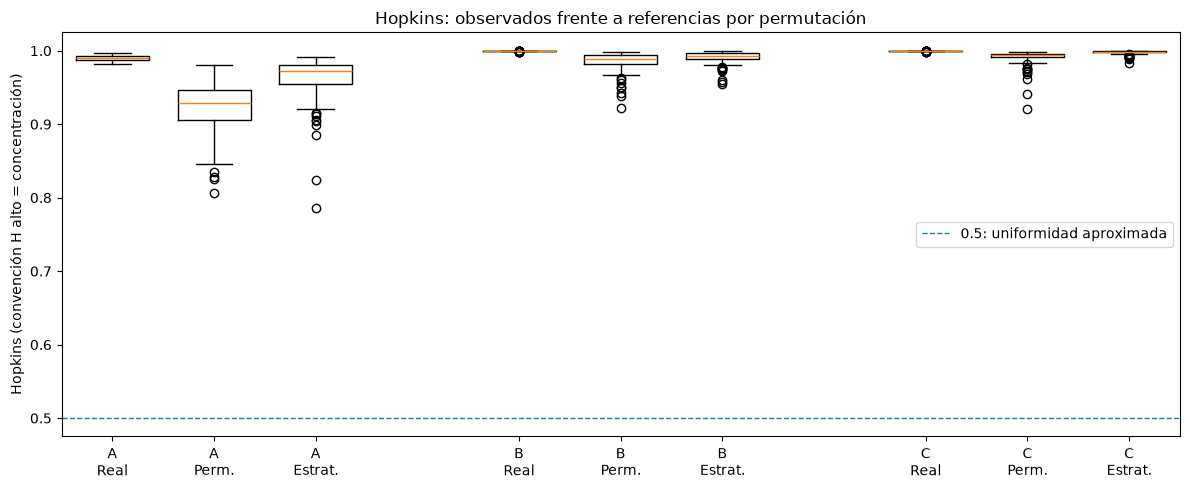

In [6]:
def hopkins(X, rng, frac=M_HOPKINS_FRAC):
    n, d = X.shape
    m = min(n-2, max(10, int(np.floor(frac*n))))
    arbol = cKDTree(X)
    idx = rng.choice(n, size=m, replace=False)
    artificial = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))
    dist_u = arbol.query(artificial, k=1)[0]
    # El primer vecino de X[idx] es el propio punto, aunque existan empates.
    dist_w = arbol.query(X[idx], k=2)[0][:, 1]
    u = np.power(dist_u, d).sum(dtype=float)
    w = np.power(dist_w, d).sum(dtype=float)
    return float(u/(u+w)) if (u+w) > 0 else float('nan')

reg_h = []
for ci, (conf, X) in enumerate(X_config.items()):
    print('Hopkins:', conf)
    for rep in range(R_HOPKINS):
        rng = np.random.default_rng(SEMILLA + ci*100_000 + 10_000 + rep)
        reg_h.append({'configuracion':conf, 'referencia':'observado',
                      'repeticion':rep+1, 'hopkins':hopkins(X, rng)})
    for tipo in ['permutacion_marginal', 'permutacion_estratificada']:
        for rep in range(B_HOPKINS_PERM):
            rng = np.random.default_rng(SEMILLA + ci*100_000 + 30_000 +
                                        (0 if tipo=='permutacion_marginal' else 10_000) + rep)
            Xr = referencia(X, tipo, rng, activo=activos_12m)
            reg_h.append({'configuracion':conf, 'referencia':tipo,
                          'repeticion':rep+1, 'hopkins':hopkins(Xr, rng)})

hopkins_detalle = pd.DataFrame(reg_h)
hopkins_resumen = (hopkins_detalle.groupby(['configuracion','referencia'], as_index=False)
                   .agg(n_repeticiones=('hopkins','size'), media=('hopkins','mean'),
                        mediana=('hopkins','median'), sd=('hopkins','std'),
                        p05=('hopkins',lambda x: x.quantile(.05)),
                        p95=('hopkins',lambda x: x.quantile(.95))))
hopkins_detalle.to_csv(SALIDAS / 'hopkins_repeticiones.csv', index=False)
hopkins_resumen.to_csv(SALIDAS / 'hopkins_resumen.csv', index=False)
display(hopkins_resumen.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
tipos = ['observado', 'permutacion_marginal', 'permutacion_estratificada']
pos, grupos, etiq = [], [], []
for i, conf in enumerate(CONFIGURACIONES):
    for j, tipo in enumerate(tipos):
        vals = hopkins_detalle.loc[(hopkins_detalle.configuracion==conf) &
                                  (hopkins_detalle.referencia==tipo), 'hopkins'].dropna()
        pos.append(i*4+j+1)
        grupos.append(vals)
        etiq.append(conf.split('_')[0]+'\n'+['Real','Perm.','Estrat.'][j])
ax.boxplot(grupos, positions=pos, widths=.72)
ax.set_xticks(pos, etiq)
ax.axhline(.5, ls='--', lw=1, label='0.5: uniformidad aproximada')
ax.set_ylabel('Hopkins (convención H alto = concentración)')
ax.set_title('Hopkins: observados frente a referencias por permutación')
ax.legend()
fig.tight_layout()
fig.savefig(SALIDAS/'hopkins_comparacion.png',dpi=180,bbox_inches='tight')
plt.show()

## 4. Gap Statistic — dispersión intra-clúster frente a referencias uniformes

Para \(K=1,\ldots,10\):

\[\mathrm{Gap}(K) = \frac{1}{B}\sum_{b=1}^B \log W_{Kb}^{*} - \log W_K.\]

Aquí \(W_K\) es la inercia de K-Means para datos reales y \(W_{Kb}^{*}\) la inercia para referencias uniformes. Regla *1-SE*: seleccionar el primer \(K\) con \(\mathrm{Gap}(K) \ge \mathrm{Gap}(K+1)-s_{K+1}\), usando \(s_K=\mathrm{sd}(\log W_{Kb}^{*})\sqrt{1+1/B}\).

**Nota:** la orientación del marco de referencia importa. Por eso se comparan dos variantes (caja original y caja rotada por PCA). La escala de Gap no se debe interpretar como una prueba universal de existencia de clústeres; la usamos como diagnóstico y apoyo para seleccionar K *dentro de cada configuración*.

Gap: A_RFM_3
  caja_uniforme: 24/99 referencias
  caja_uniforme: 48/99 referencias
  caja_uniforme: 72/99 referencias
  caja_uniforme: 96/99 referencias
  Completado caja_uniforme.
  caja_pca: 24/99 referencias
  caja_pca: 48/99 referencias
  caja_pca: 72/99 referencias
  caja_pca: 96/99 referencias
  Completado caja_pca.
Gap: B_RFM_ratio_4
  caja_uniforme: 24/99 referencias
  caja_uniforme: 48/99 referencias
  caja_uniforme: 72/99 referencias
  caja_uniforme: 96/99 referencias
  Completado caja_uniforme.
  caja_pca: 24/99 referencias
  caja_pca: 48/99 referencias
  caja_pca: 72/99 referencias
  caja_pca: 96/99 referencias
  Completado caja_pca.
Gap: C_W_6
  caja_uniforme: 24/99 referencias
  caja_uniforme: 48/99 referencias
  caja_uniforme: 72/99 referencias
  caja_uniforme: 96/99 referencias
  Completado caja_uniforme.
  caja_pca: 24/99 referencias
  caja_pca: 48/99 referencias
  caja_pca: 72/99 referencias
  caja_pca: 96/99 referencias
  Completado caja_pca.


,configuracion,referencia,K_1SE,K_gap_max,gap_max,B
0,A_RFM_3,caja_pca,7,10,1.3780,99
1,A_RFM_3,caja_uniforme,5,10,0.7352,99
2,B_RFM_ratio_4,caja_pca,10,10,1.7665,99
3,B_RFM_ratio_4,caja_uniforme,10,10,1.2754,99
4,C_W_6,caja_pca,10,10,1.7539,99
5,C_W_6,caja_uniforme,10,10,1.4422,99


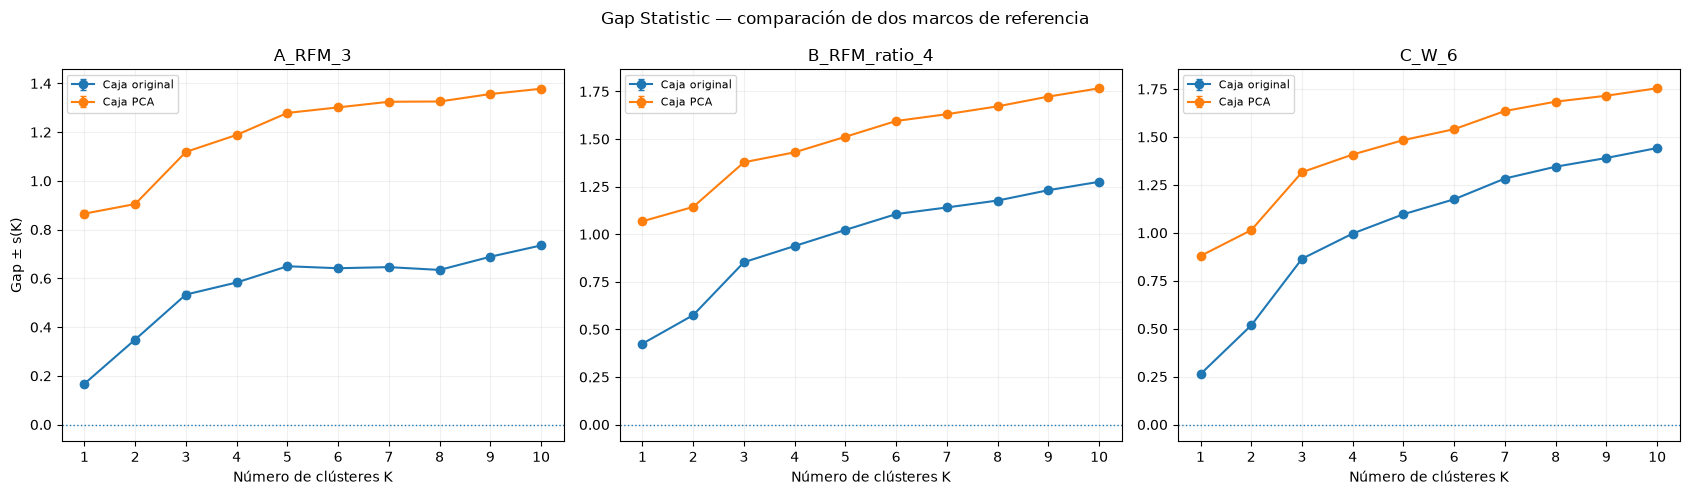

In [7]:
reg_gap = []
for ci, (conf, X) in enumerate(X_config.items()):
    print('Gap:', conf)
    inercias_obs = {k: float(kmeans(X,k,SEMILLA,N_INIT_GAP).inertia_) for k in K_GAP}
    pca = PCA(n_components=X.shape[1],svd_solver='full').fit(X)
    for ri, tipo in enumerate(['caja_uniforme', 'caja_pca']):
        logs = {k:[] for k in K_GAP}
        t0 = time.monotonic()
        for rep in range(B_GAP):
            rng = np.random.default_rng(SEMILLA + ci*1_000_000 + ri*100_000 + rep)
            Xref = referencia(X,tipo,rng,pca=pca)
            # Una misma muestra de referencia por repetición para todos los K
            for k in K_GAP:
                mod = kmeans(Xref,k,SEMILLA+10_000+rep,N_INIT_GAP)
                logs[k].append(float(np.log(max(mod.inertia_,1e-200))))
            if (rep+1)%max(1,B_GAP//4)==0:
                print(f'  {tipo}: {rep+1}/{B_GAP} referencias')
        for k in K_GAP:
            v = np.array(logs[k],dtype=float)
            log_observado = np.log(max(inercias_obs[k],1e-200))
            sd_ref = float(v.std(ddof=1))
            reg_gap.append({'configuracion':conf,'referencia':tipo,'k':k,
                            'B':B_GAP,'log_W_observado':log_observado,
                            'media_log_W_referencia':float(v.mean()),
                            'sd_log_W_referencia':sd_ref,
                            'gap':float(v.mean()-log_observado),
                            'se_gap':float(np.sqrt(1+1/B_GAP)*sd_ref)})
        print(f'  Completado {tipo}.')

gap_tabla = pd.DataFrame(reg_gap).sort_values(['configuracion','referencia','k']).reset_index(drop=True)
gap_tabla['cumple_regla_1se'] = False
reg_gap_k = []
for (conf, tipo), sub in gap_tabla.groupby(['configuracion','referencia'],sort=False):
    sub = sub.sort_values('k')
    ks = sub.k.to_numpy()
    g = sub.gap.to_numpy()
    se = sub.se_gap.to_numpy()
    cumple = g[:-1] >= (g[1:]-se[1:])
    idx = sub.index.to_numpy()[:-1]
    gap_tabla.loc[idx,'cumple_regla_1se'] = cumple
    primero = int(ks[np.flatnonzero(cumple)[0]]) if cumple.any() else int(ks[np.argmax(g)])
    reg_gap_k.append({'configuracion':conf,'referencia':tipo,
                      'K_1SE':primero,'K_gap_max':int(ks[np.argmax(g)]),
                      'gap_max':float(g.max()),'B':B_GAP})

gap_seleccion = pd.DataFrame(reg_gap_k)
gap_tabla.to_csv(SALIDAS/'gap_por_configuracion_y_referencia.csv',index=False)
gap_seleccion.to_csv(SALIDAS/'gap_K_sugerido.csv',index=False)
display(gap_seleccion.round(4))

fig, axes = plt.subplots(1,3,figsize=(17,5),sharex=True)
for ax,(conf,_) in zip(axes,CONFIGURACIONES.items()):
    for tipo in ['caja_uniforme','caja_pca']:
        t=gap_tabla.loc[(gap_tabla.configuracion==conf)&(gap_tabla.referencia==tipo)]
        ax.errorbar(t.k,t.gap,yerr=t.se_gap,marker='o',capsize=2,
                    label='Caja original' if tipo=='caja_uniforme' else 'Caja PCA')
    ax.set_title(conf)
    ax.set_xticks(K_GAP)
    ax.set_xlabel('Número de clústeres K')
    ax.axhline(0,ls=':',lw=1)
    ax.grid(alpha=.18)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Gap ± s(K)')
fig.suptitle('Gap Statistic — comparación de dos marcos de referencia')
fig.tight_layout()
fig.savefig(SALIDAS/'gap_caja_vs_pca.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Referencias aleatorizadas — Silhouette de las soluciones candidatas

Para cada candidato se compara la Silhouette **exacta en todos los clientes de TRAIN** con la distribución de Silhouette obtenida por K-Means sobre referencias permutadas de idéntico tamaño. Cada referencia usa el **mismo K y el mismo `n_init`** que la solución observada.

Se calcula \(\Delta = S_{\mathrm{real}}-\overline{S}_{\mathrm{referencia}}\) y una proporción de Monte Carlo \(p_{MC}=(1+\#\{S_{b}^{*}\ge S_{\mathrm{real}}\})/(B+1)\). Esta última **no debe llamarse prueba confirmatoria** si los candidatos se seleccionaron por buen desempeño en los mismos datos; además depende del modelo nulo y no corrige automáticamente por selección múltiple. Se muestra una corrección conservadora de Bonferroni para los candidatos visibles, pero no reemplaza una validación confirmatoria externa.

**La permutación estratificada es la comparación más informativa para nuestros ceros**, pues conserva la diferencia global entre clientes activos/inactivos. Aun así, permutar los componentes del ratio crea combinaciones incompatibles con su definición, de modo que tampoco constituye una referencia generativa perfecta.

Referencias aleatorizadas: A_RFM_3 K = 2
   permutacion_marginal completada
   permutacion_estratificada completada
Referencias aleatorizadas: B_RFM_ratio_4 K = 3
   permutacion_marginal completada
   permutacion_estratificada completada
Referencias aleatorizadas: B_RFM_ratio_4 K = 4
   permutacion_marginal completada
   permutacion_estratificada completada
Referencias aleatorizadas: C_W_6 K = 2
   permutacion_marginal completada
   permutacion_estratificada completada
Referencias aleatorizadas: C_W_6 K = 3
   permutacion_marginal completada
   permutacion_estratificada completada
Referencias aleatorizadas: C_W_6 K = 5
   permutacion_marginal completada
   permutacion_estratificada completada

Resultados guardados correctamente.


,configuracion,k,referencia,B,silhouette_real,silhouette_null_media,silhouette_null_sd,silhouette_null_p95,delta_silhouette,n_nulos_superiores_o_iguales,p_MC_exploratorio,p_MC_bonferroni_candidatos
0,A_RFM_3,2,permutacion_marginal,199,0.4465,0.3976,0.0071,0.4080,0.0489,0,0.005,0.03
1,A_RFM_3,2,permutacion_estratificada,199,0.4465,0.3818,0.0098,0.3980,0.0647,0,0.005,0.03
2,B_RFM_ratio_4,3,permutacion_marginal,199,0.4453,0.2757,0.0014,0.2781,0.1696,0,0.005,0.03
3,B_RFM_ratio_4,3,permutacion_estratificada,199,0.4453,0.2976,0.0039,0.3039,0.1477,0,0.005,0.03
4,B_RFM_ratio_4,4,permutacion_marginal,199,0.4621,0.3071,0.0024,0.3111,0.1550,0,0.005,0.03
5,B_RFM_ratio_4,4,permutacion_estratificada,199,0.4621,0.3153,0.0088,0.3245,0.1468,0,0.005,0.03
6,C_W_6,2,permutacion_marginal,199,0.4597,0.2524,0.0052,0.2604,0.2072,0,0.005,0.03
7,C_W_6,2,permutacion_estratificada,199,0.4597,0.3963,0.0023,0.4003,0.0634,0,0.005,0.03
8,C_W_6,3,permutacion_marginal,199,0.4436,0.2537,0.0232,0.2686,0.1899,0,0.005,0.03
9,C_W_6,3,permutacion_estratificada,199,0.4436,0.2336,0.0053,0.2507,0.2100,0,0.005,0.03


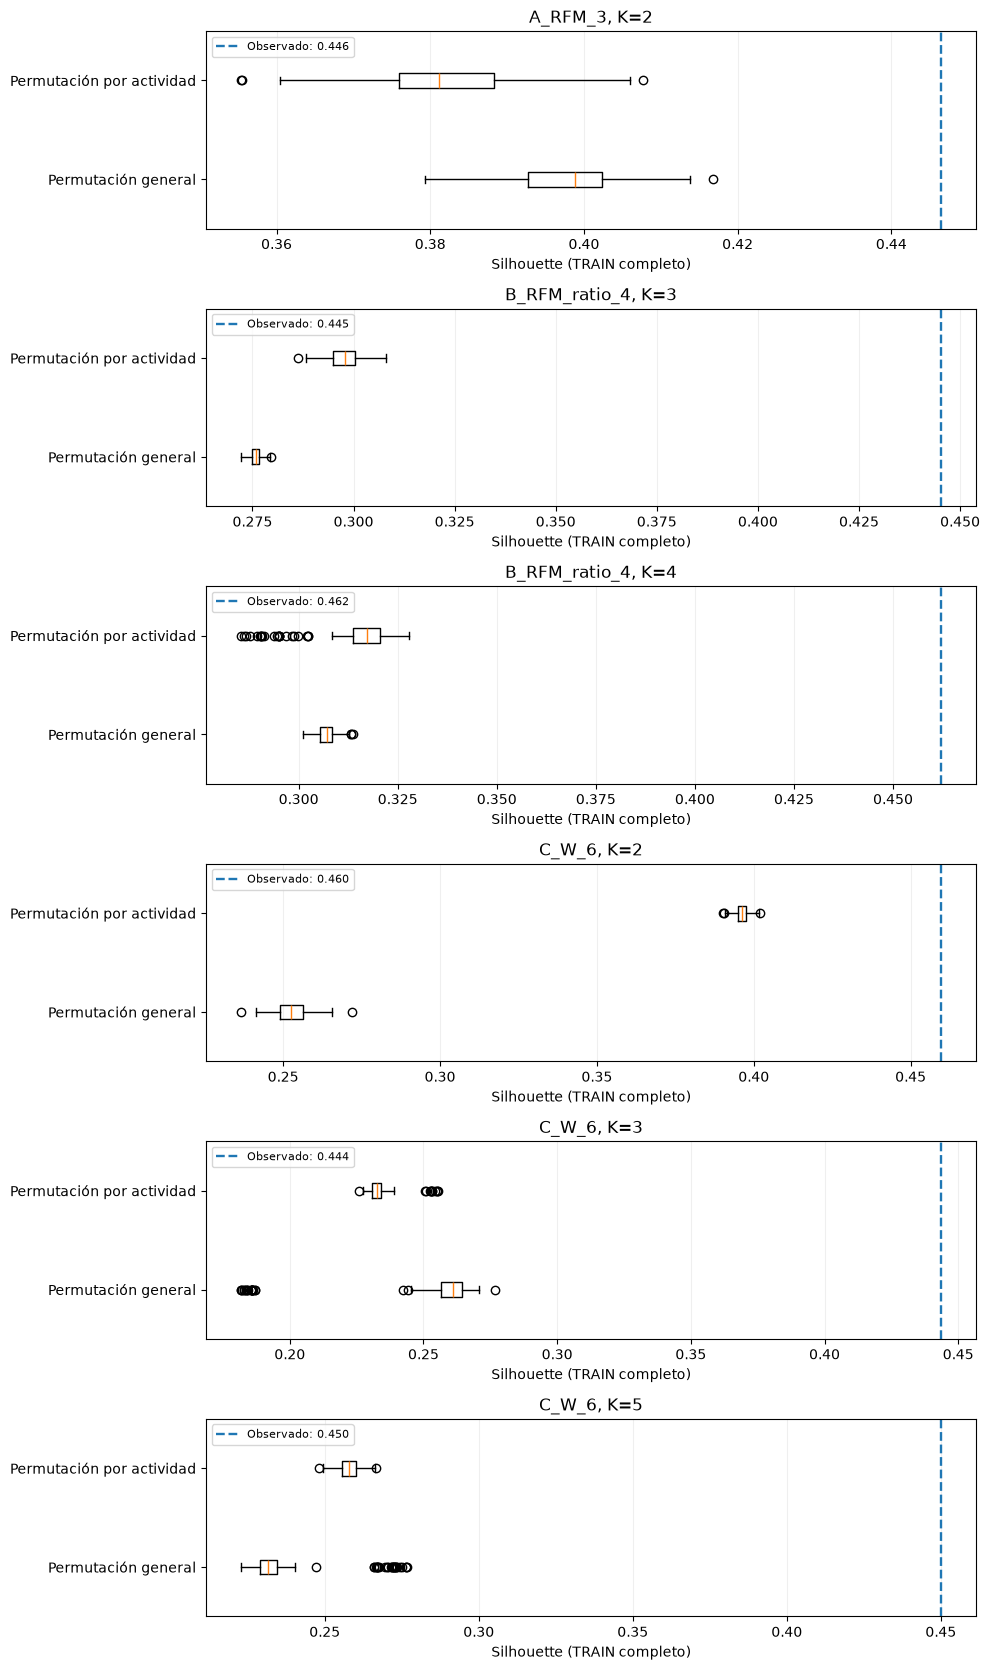


Análisis de referencias aleatorizadas completado.


In [8]:

# ============================================================
# 5. REFERENCIAS ALEATORIZADAS — SILHOUETTE
# Compatible con Matplotlib 3.11.2
# ============================================================

reg_aleatorios, reg_obs = [], []

for ci, (conf, k) in enumerate(CANDIDATOS):

    X = X_config[conf]

    print("Referencias aleatorizadas:", conf, "K =", k)

    # Modelo original sobre TRAIN completo
    mod_real = kmeans(X, k, SEMILLA, N_INIT_SIL)

    s_real = float(
        silhouette_score(X, mod_real.labels_)
    )

    reg_obs.append({
        "configuracion": conf,
        "k": k,
        "silhouette_real": s_real,
        "inercia_real": float(mod_real.inertia_)
    })

    # Comparación con referencias aleatorizadas
    for ri, tipo in enumerate([
        "permutacion_marginal",
        "permutacion_estratificada"
    ]):

        for rep in range(B_PERM):

            rng = np.random.default_rng(
                SEMILLA
                + 3_000_000
                + ci * 100_000
                + ri * 10_000
                + rep
            )

            Xr = referencia(
                X,
                tipo,
                rng,
                activo=activos_12m
            )

            modr = kmeans(
                Xr,
                k,
                SEMILLA + 20_000 + rep,
                N_INIT_SIL
            )

            s_ref = float(
                silhouette_score(Xr, modr.labels_)
            )

            reg_aleatorios.append({
                "configuracion": conf,
                "k": k,
                "referencia": tipo,
                "repeticion": rep + 1,
                "silhouette_ref": s_ref,
                "silhouette_real": s_real
            })

        print("  ", tipo, "completada")

# ============================================================
# 6. CONSTRUIR DATAFRAMES
# ============================================================

aleatorizados_detalle = pd.DataFrame(reg_aleatorios)
observados_candidatos = pd.DataFrame(reg_obs)

resumen_refs = []

for (conf, k, tipo), s in aleatorizados_detalle.groupby(
    ["configuracion", "k", "referencia"],
    sort=False
):

    v = s["silhouette_ref"].to_numpy()

    real = float(s["silhouette_real"].iloc[0])

    B = len(v)

    superior = int(np.sum(v >= real))

    p_mc = (superior + 1) / (B + 1)

    resumen_refs.append({
        "configuracion": conf,
        "k": k,
        "referencia": tipo,
        "B": B,
        "silhouette_real": real,
        "silhouette_null_media": float(v.mean()),
        "silhouette_null_sd": float(v.std(ddof=1)),
        "silhouette_null_p95": float(np.quantile(v, 0.95)),
        "delta_silhouette": float(real - v.mean()),
        "n_nulos_superiores_o_iguales": superior,
        "p_MC_exploratorio": p_mc
    })

comparacion_refs = pd.DataFrame(resumen_refs)

# Ajuste conservador por los candidatos evaluados
comparacion_refs["p_MC_bonferroni_candidatos"] = np.minimum(
    1.0,
    comparacion_refs["p_MC_exploratorio"] * len(CANDIDATOS)
)

# ============================================================
# 7. GUARDAR RESULTADOS ANTES DE GENERAR GRÁFICOS
# ============================================================

SALIDAS.mkdir(parents=True, exist_ok=True)

comparacion_refs.to_csv(
    SALIDAS / "comparacion_silhouette_vs_referencias.csv",
    index=False
)

aleatorizados_detalle.to_csv(
    SALIDAS / "referencias_aleatorizadas_repeticiones.csv",
    index=False
)

observados_candidatos.to_csv(
    SALIDAS / "silhouette_real_candidatos.csv",
    index=False
)

print("\nResultados guardados correctamente.")
display(comparacion_refs.round(4))

# ============================================================
# 8. GRÁFICOS — COMPATIBLE CON MATPLOTLIB 3.11.2
# ============================================================

fig, axes = plt.subplots(
    len(CANDIDATOS),
    1,
    figsize=(10, 2.8 * len(CANDIDATOS))
)

axes = np.atleast_1d(axes)

for ax, (conf, k) in zip(axes, CANDIDATOS):

    serie = []

    for tipo in [
        "permutacion_marginal",
        "permutacion_estratificada"
    ]:

        v = aleatorizados_detalle.loc[
            (aleatorizados_detalle["configuracion"] == conf)
            & (aleatorizados_detalle["k"] == k)
            & (aleatorizados_detalle["referencia"] == tipo),
            "silhouette_ref"
        ]

        serie.append(v.to_numpy())

    # CORRECCIÓN PARA MATPLOTLIB 3.11.2
    ax.boxplot(
        serie,
        tick_labels=[
            "Permutación general",
            "Permutación por actividad"
        ],
        orientation="horizontal"
    )

    real = observados_candidatos.loc[
        (observados_candidatos["configuracion"] == conf)
        & (observados_candidatos["k"] == k),
        "silhouette_real"
    ].iloc[0]

    ax.axvline(
        real,
        linestyle="--",
        linewidth=1.7,
        label=f"Observado: {real:.3f}"
    )

    ax.set_title(f"{conf}, K={k}")
    ax.set_xlabel("Silhouette (TRAIN completo)")
    ax.legend(fontsize=8)
    ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

fig.savefig(
    SALIDAS / "comparacion_silhouette_permutaciones.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nAnálisis de referencias aleatorizadas completado.")


## 6. Síntesis y protocolo de interpretación

La tabla conjunta **no declara automáticamente que existen clústeres naturales**. Reúne indicadores con supuestos diferentes para facilitar la discusión.

Preguntas clave:

1. ¿El Hopkins observado se aleja del 0,5 y, sobre todo, difiere de Hopkins sobre columnas permutadas? Si las permutaciones también arrojan Hopkins altos, los ceros/asimetría pueden explicar parte de la señal.
2. ¿Gap sugiere K similares para la caja original y la caja PCA? Si no, hay sensibilidad al marco de referencia.
3. ¿La Silhouette real supera de forma consistente las referencias marginal y estratificada? El contraste estratificado permite estudiar si hay estructura adicional a la dicotomía de compra reciente; **no** prueba naturalidad de segmentos.
4. ¿Concuerdan estos diagnósticos con ARI/Jaccard, tamaños y perfiles comerciales de los notebooks anteriores?

Si hay discordancias, documentarlas. La inferencia correcta puede ser *segmentos comerciales operativos y reproducibles*, incluso sin evidencia concluyente de grupos naturales. El objetivo no es forzar una conclusión positiva.

In [9]:
h_real=hopkins_resumen.query("referencia == 'observado'")[[
    'configuracion','media','mediana','p05','p95'
]].rename(columns={'media':'hopkins_media','mediana':'hopkins_mediana',
                   'p05':'hopkins_p05','p95':'hopkins_p95'})
resumen_final=(comparacion_refs.merge(h_real,on='configuracion',how='left')
               .merge(gap_seleccion[['configuracion','referencia','K_1SE']],
                      left_on=['configuracion'],right_on=['configuracion'],how='left',
                      suffixes=('','_gap')))
# Gap produce dos filas por configuración: cada referencia de Silhouette se
# combina con las dos referencias Gap. No es un duplicado de resultados estadísticos.
resumen_final=resumen_final.rename(columns={'referencia':'referencia_permutacion',
                                            'referencia_gap':'referencia_gap'})
resumen_final.to_csv(SALIDAS/'resumen_evidencia_estructura.csv',index=False)
print('Resumen (una fila por candidato x permutación x referencia Gap):')
display(resumen_final[['configuracion','k','referencia_permutacion','referencia_gap',
                       'hopkins_mediana','K_1SE','silhouette_real',
                       'silhouette_null_media','delta_silhouette',
                       'p_MC_exploratorio']].round(4))

hash_csv=hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()
manifest={
    'datos_csv':str(RUTA_CSV),'hash_sha256_csv':hash_csv,'n_train':int(len(df)),
    'modo':MODO,'semilla':SEMILLA,'B_GAP':B_GAP,'B_PERM':B_PERM,
    'R_HOPKINS':R_HOPKINS,'B_HOPKINS_PERM':B_HOPKINS_PERM,
    'N_INIT_GAP':N_INIT_GAP,'N_INIT_SIL':N_INIT_SIL,'K_GAP':K_GAP,
    'CANDIDATOS':[[c,int(k)] for c,k in CANDIDATOS],
    'CONFIGURACIONES':CONFIGURACIONES,
    'comentario':'Exploratorio: contrastes dependen del modelo nulo; no prueban clústeres naturales',
}
(SALIDAS/'manifest_configuracion.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Archivos guardados en:',SALIDAS)

Resumen (una fila por candidato x permutación x referencia Gap):


,configuracion,k,referencia_permutacion,referencia_gap,hopkins_mediana,K_1SE,silhouette_real,silhouette_null_media,delta_silhouette,p_MC_exploratorio
0,A_RFM_3,2,permutacion_marginal,caja_pca,0.9904,7,0.4465,0.3976,0.0489,0.005
1,A_RFM_3,2,permutacion_marginal,caja_uniforme,0.9904,5,0.4465,0.3976,0.0489,0.005
2,A_RFM_3,2,permutacion_estratificada,caja_pca,0.9904,7,0.4465,0.3818,0.0647,0.005
3,A_RFM_3,2,permutacion_estratificada,caja_uniforme,0.9904,5,0.4465,0.3818,0.0647,0.005
4,B_RFM_ratio_4,3,permutacion_marginal,caja_pca,0.9998,10,0.4453,0.2757,0.1696,0.005
5,B_RFM_ratio_4,3,permutacion_marginal,caja_uniforme,0.9998,10,0.4453,0.2757,0.1696,0.005
6,B_RFM_ratio_4,3,permutacion_estratificada,caja_pca,0.9998,10,0.4453,0.2976,0.1477,0.005
7,B_RFM_ratio_4,3,permutacion_estratificada,caja_uniforme,0.9998,10,0.4453,0.2976,0.1477,0.005
8,B_RFM_ratio_4,4,permutacion_marginal,caja_pca,0.9998,10,0.4621,0.3071,0.1550,0.005
9,B_RFM_ratio_4,4,permutacion_marginal,caja_uniforme,0.9998,10,0.4621,0.3071,0.1550,0.005


Archivos guardados en: c:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_estructura_kmeans_min80


## 7. Texto metodológico sugerido para la tesis (ajustar después de obtener resultados)

> Con el propósito de examinar la tendencia de los datos a formar agrupamientos, se aplicaron tres análisis complementarios sobre las variables transaccionales de TRAIN. Primero, se calculó el estadístico de Hopkins mediante muestreos repetidos, con una referencia uniforme definida en el rango multivariante observado. Segundo, se estimó el estadístico Gap para K entre 1 y 10, utilizando referencias uniformes en la caja de datos estandarizados y en coordenadas principales. Finalmente, se comparó la Silhouette de soluciones candidatas con distribuciones obtenidas de permutaciones marginales y permutaciones condicionadas a actividad transaccional en los últimos doce meses. Estos procedimientos se interpretaron como evidencia relativa a los modelos de referencia y no como demostración concluyente de grupos naturales. La elección final también consideró estabilidad ante submuestreo e interpretabilidad comercial.

### Limitaciones que deben reportarse

- **No normalidad, ceros y empates:** la hipótesis uniforme de Hopkins puede ser poco realista para estos datos; incluso una nube unimodal no uniforme puede producir Hopkins alto.
- **Región muestral no rectangular:** valores de la razón y de las variables mensuales no son combinaciones libres; las cajas uniformes de Gap y Hopkins incluyen combinaciones inviables. La rotación PCA atenúa la orientación arbitraria, pero no elimina el problema.
- **Permutación general:** conserva distribuciones de cada variable, destruye todas las asociaciones; puede crear clientes sintéticos incoherentes.
- **Permutación estratificada:** preserva estructuras gruesas de ceros y compras recientes; sigue destruyendo dependencia dentro de cada estrato.
- **Reutilización de TRAIN:** la misma muestra se empleó para proponer configuraciones y K. Las proporciones Monte Carlo son evidencias exploratorias, no p-valores confirmatorios completamente ajustados por búsqueda.
- **Selección y interpretación:** preferir segmentos robustos y comercialmente interpretables antes que presentar una afirmación exagerada de clusters naturales.

### Referencias metodológicas

- Tibshirani, R., Walther, G., & Hastie, T. (2001). *Estimating the Number of Clusters in a Data Set Via the Gap Statistic*. Journal of the Royal Statistical Society: Series B, 63(2), 411–423. https://doi.org/10.1111/1467-9868.00293
- Wright, K. (2022). *A protocol for Hopkins statistic*. https://cloud.r-project.org/web/packages/hopkins/vignettes/hopkins_protocol.html
- Wright, K. (2022). *Will the Real Hopkins Statistic Please Stand Up?* The R Journal. https://rjournal.github.io/articles/RJ-2022-055/

**Próximo paso:** comparar los archivos `gap_K_sugerido.csv`, `comparacion_silhouette_vs_referencias.csv` y `hopkins_resumen.csv` junto con `comparacion_candidatos_con_estabilidad.csv` del notebook anterior.